# Empleo y vivienda en España: análisis exploratorio

Este notebook explora los datos que alimentan el [panel](https://munguiagomezj.github.io/Proyecto3/). Las preguntas:

1. ¿Cómo ha evolucionado el paro en España frente a la UE desde 2008?
2. ¿Qué comunidades se han recuperado más desde la crisis de 2013?
3. ¿El paro juvenil sigue al paro general?
4. ¿Cómo ha evolucionado el precio de la vivienda?

Los datos se descargan de Eurostat con `scripts/descargar_datos.py` y se limpian con `scripts/procesar_datos.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from analisis.indicadores import ranking_regiones, serie

DATOS = Path("../data/processed")
mensual = pd.read_csv(DATOS / "paro_mensual.csv", parse_dates=["fecha"])
regiones = pd.read_csv(DATOS / "paro_regiones.csv")
vivienda = pd.read_csv(DATOS / "precio_vivienda.csv", parse_dates=["fecha"])

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#a3a29b"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e8e7e2", "font.size": 11})

print(f"Paro mensual: {len(mensual)} filas, de {mensual.fecha.min():%m/%Y} a {mensual.fecha.max():%m/%Y}")
print(f"Paro regional: {regiones.region.nunique()} territorios, {regiones.anio.min()}–{regiones.anio.max()}")
print(f"Vivienda: {len(vivienda)} filas, hasta {vivienda.fecha.max():%m/%Y}")
mensual.head()

Paro mensual: 896 filas, de 01/2008 a 08/2026
Paro regional: 20 territorios, 2008–2025
Vivienda: 132 filas, hasta 04/2026


,fecha,zona,grupo,tasa
0,2008-01-01,España,Menores de 25,20.1
1,2008-02-01,España,Menores de 25,20.5
2,2008-03-01,España,Menores de 25,21.0
3,2008-04-01,España,Menores de 25,22.6
4,2008-05-01,España,Menores de 25,23.6


## Calidad de los datos

Antes de analizar, comprobamos que no falten valores ni haya duplicados.

In [2]:
for nombre, df in {"mensual": mensual, "regiones": regiones, "vivienda": vivienda}.items():
    print(f"{nombre:9} nulos: {df.isna().sum().sum()}  duplicados: {df.duplicated().sum()}")

mensual   nulos: 0  duplicados: 0
regiones  nulos: 0  duplicados: 0
vivienda  nulos: 0  duplicados: 0


## 1. El paro en España frente a la UE

La brecha con Europa es el dato más estable de la serie: España siempre está por encima.

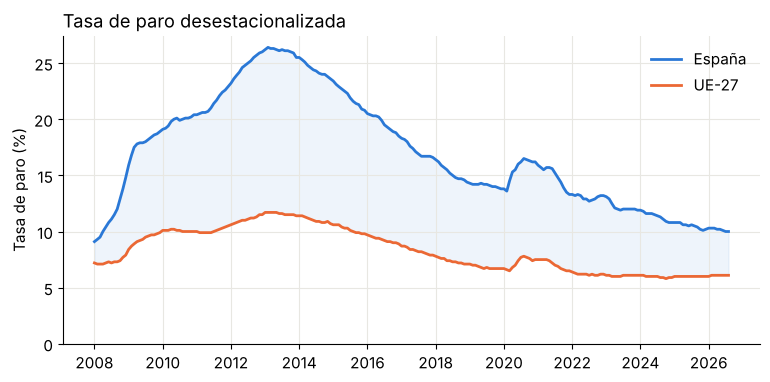

Brecha máxima: 14.7 puntos (02/2013)
Brecha mínima: 1.9 puntos (01/2008)
Brecha actual: 3.9 puntos (08/2026)


In [3]:
es = serie(mensual, zona="España", grupo="Total")
ue = serie(mensual, zona="UE-27", grupo="Total")
brecha = (es - ue).dropna()

fig, ax = plt.subplots()
ax.plot(es.index, es, color=AZUL, lw=2, label="España")
ax.plot(ue.index, ue, color=NARANJA, lw=2, label="UE-27")
ax.fill_between(brecha.index, ue.loc[brecha.index], es.loc[brecha.index], color=AZUL, alpha=0.08)
ax.set_ylabel("Tasa de paro (%)")
ax.set_ylim(0)
ax.legend(frameon=False)
ax.set_title("Tasa de paro desestacionalizada", loc="left")
plt.show()

print(f"Brecha máxima: {brecha.max():.1f} puntos ({brecha.idxmax():%m/%Y})")
print(f"Brecha mínima: {brecha.min():.1f} puntos ({brecha.idxmin():%m/%Y})")
print(f"Brecha actual: {brecha.iloc[-1]:.1f} puntos ({brecha.index[-1]:%m/%Y})")

## 2. ¿Qué comunidades se han recuperado más desde 2013?

Comparamos la tasa de paro de 2013 (el peor año) con la del último año disponible, en puntos y en porcentaje.

In [4]:
ultimo = int(regiones.anio.max())
antes = ranking_regiones(regiones, "Total", 2013).set_index("region")["tasa"]
ahora = ranking_regiones(regiones, "Total", ultimo).set_index("region")["tasa"]
recuperacion = pd.DataFrame({"2013": antes, str(ultimo): ahora})
recuperacion["bajada_puntos"] = recuperacion["2013"] - recuperacion[str(ultimo)]
recuperacion["bajada_%"] = recuperacion["bajada_puntos"] / recuperacion["2013"] * 100
recuperacion.sort_values("bajada_%", ascending=False).round(1)

,2013,2025,bajada_puntos,bajada_%
region,,,,
Cantabria,20.5,7.3,13.2,64.4
Cataluña,23.1,8.4,14.7,63.6
Asturias,24.1,8.8,15.3,63.5
Aragón,21.4,8.0,13.4,62.6
Galicia,22.1,8.4,13.7,62.0
Castilla y León,21.8,8.6,13.2,60.6
Baleares,22.3,8.8,13.5,60.5
Canarias,33.7,13.5,20.2,59.9
Madrid,19.8,8.0,11.8,59.6


Correlación entre el paro de 2013 y la bajada en puntos: 0.54


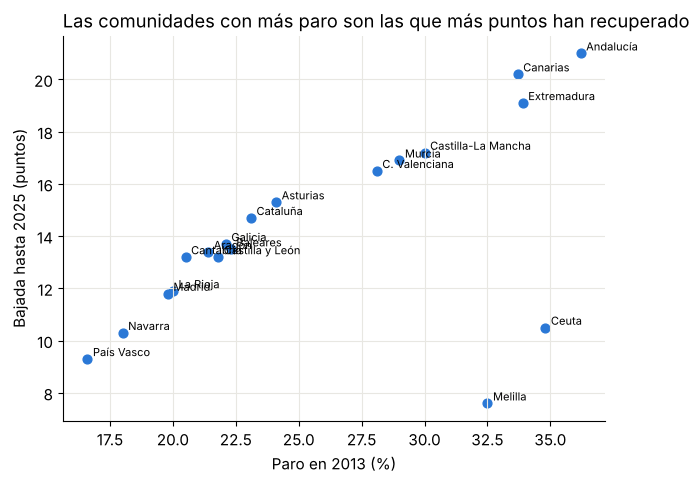

In [5]:
corr = recuperacion["2013"].corr(recuperacion["bajada_puntos"])
print(f"Correlación entre el paro de 2013 y la bajada en puntos: {corr:.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(recuperacion["2013"], recuperacion["bajada_puntos"], color=AZUL, s=40)
for region, fila in recuperacion.iterrows():
    ax.annotate(region, (fila["2013"], fila["bajada_puntos"]), fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("Paro en 2013 (%)")
ax.set_ylabel(f"Bajada hasta {ultimo} (puntos)")
ax.set_title("Las comunidades con más paro son las que más puntos han recuperado", loc="left")
plt.show()

**Lectura:** las comunidades que partían de un paro más alto tienden a haber bajado más puntos (correlación moderada, 0,54). Pero el orden entre ellas apenas ha cambiado: quien tenía más paro en 2013 sigue teniéndolo hoy.

In [6]:
orden_2013 = recuperacion["2013"].rank()
orden_hoy = recuperacion[str(ultimo)].rank()
print(f"Correlación de rangos (Spearman) entre 2013 y {ultimo}: {orden_2013.corr(orden_hoy):.2f}")

Correlación de rangos (Spearman) entre 2013 y 2025: 0.95


## 3. ¿El paro juvenil sigue al paro general?

Para cada comunidad y año comparamos la tasa de 15 a 24 años con la tasa total.

Correlación paro total vs juvenil: 0.93


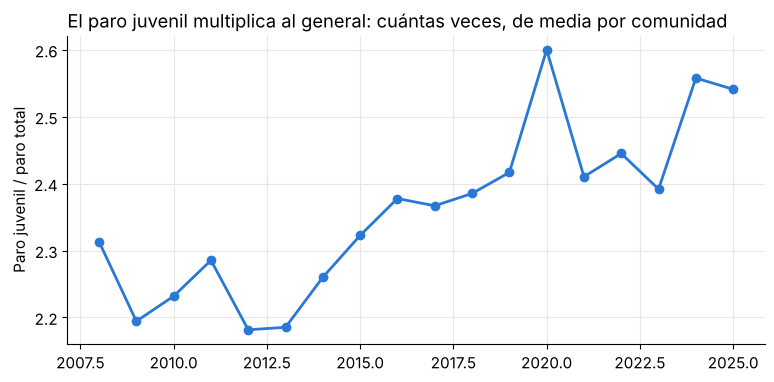

anio
2021    2.41
2022    2.45
2023    2.39
2024    2.56
2025    2.54
dtype: float64

In [7]:
ancho = regiones[regiones.codigo != "ES"].pivot_table(index=["region", "anio"], columns="grupo", values="tasa")
ratio = (ancho["15 a 24 años"] / ancho["Total"]).groupby("anio").mean()
print(f"Correlación paro total vs juvenil: {ancho['Total'].corr(ancho['15 a 24 años']):.2f}")

fig, ax = plt.subplots()
ax.plot(ratio.index, ratio, color=AZUL, lw=2, marker="o")
ax.set_ylabel("Paro juvenil / paro total")
ax.set_title("El paro juvenil multiplica al general: cuántas veces, de media por comunidad", loc="left")
plt.show()
ratio.round(2).tail()

## 4. El precio de la vivienda

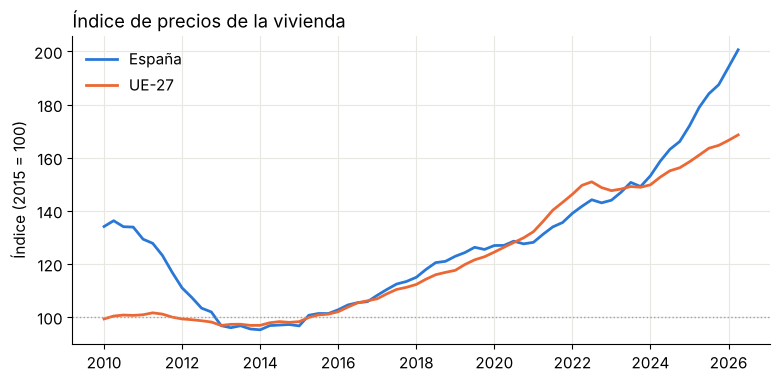

Mínimo en España: 95.2 (2014-01)
Subida desde el mínimo: 111 %
Último trimestre en que España estaba por debajo de la UE: 2023-04


In [8]:
viv_es = serie(vivienda, "indice_2015", zona="España")
viv_ue = serie(vivienda, "indice_2015", zona="UE-27")

fig, ax = plt.subplots()
ax.plot(viv_es.index, viv_es, color=AZUL, lw=2, label="España")
ax.plot(viv_ue.index, viv_ue, color=NARANJA, lw=2, label="UE-27")
ax.axhline(100, color=GRIS, ls=":", lw=1)
ax.set_ylabel("Índice (2015 = 100)")
ax.legend(frameon=False)
ax.set_title("Índice de precios de la vivienda", loc="left")
plt.show()

cruce = (viv_es > viv_ue)[viv_es.index >= "2016-01-01"]
print(f"Mínimo en España: {viv_es.min():.1f} ({viv_es.idxmin():%Y-%m})")
print(f"Subida desde el mínimo: {viv_es.iloc[-1] / viv_es.min() * 100 - 100:.0f} %")
print(f"Último trimestre en que España estaba por debajo de la UE: {cruce[~cruce].index.max():%Y-%m}")

## Conclusiones

- El paro en España ha bajado a menos de la mitad desde el máximo de 2013, pero sigue varios puntos por encima de la media de la UE.
- La recuperación ha sido general y el orden entre comunidades casi no ha cambiado (correlación de rangos de 0,95 entre 2013 y el último año).
- El paro juvenil se mueve con el general (correlación de 0,93), pero lo multiplica cada vez más: de unas 2,2 veces en 2013 a unas 2,5 en los últimos años. Los jóvenes se han beneficiado menos de la recuperación.
- La vivienda ha duplicado su precio desde el mínimo de 2014 y desde mediados de 2023 su subida acumulada desde 2015 supera a la de la media europea.

**Límites:** son tasas agregadas; no distinguen el tipo de contrato, la temporalidad ni los salarios, que también influyen en el acceso a la vivienda.